<a href="https://colab.research.google.com/github/nazaninharirian18363-cmyk/two-tower-movie-recsys/blob/main/two_tower_recommender.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎬 Two-Tower Movie Recommender (MovieLens)



In [1]:
!pip -q install gradio sentence-transformers

In [2]:
import os, re, math, random, zipfile, urllib.request
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


## 1) دانلود داده

In [3]:
URL = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"
DATA_DIR = "ml-latest-small"
if not os.path.exists(DATA_DIR):
    urllib.request.urlretrieve(URL, "ml.zip")
    with zipfile.ZipFile("ml.zip") as z:
        z.extractall(".")

ratings = pd.read_csv(f"{DATA_DIR}/ratings.csv")
movies  = pd.read_csv(f"{DATA_DIR}/movies.csv")
print(ratings.shape, movies.shape)
ratings.head()

(100836, 4) (9742, 3)


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


## 2) پیش‌پردازش



In [4]:
pos = ratings[ratings.rating >= 4.0].copy()
cnt = pos.groupby("userId").size()
pos = pos[pos.userId.isin(cnt[cnt >= 5].index)]
pos = pos.sort_values(["userId", "timestamp"])

# ایندکس‌گذاری پیوسته
user_ids = np.sort(pos.userId.unique())
movie_ids = np.sort(movies.movieId.unique())
u2i = {u: k for k, u in enumerate(user_ids)}
m2i = {m: k for k, m in enumerate(movie_ids)}
n_users, n_items = len(user_ids), len(movie_ids)
pos["u"] = pos.userId.map(u2i)
pos["i"] = pos.movieId.map(m2i)

# تقسیم زمانی
pos["rev_rank"] = pos.groupby("u").cumcount(ascending=False)
test_df  = pos[pos.rev_rank == 0]
val_df   = pos[pos.rev_rank == 1]
train_df = pos[pos.rev_rank >= 2]
print(f"users={n_users}  items={n_items}  train={len(train_df)}  val={len(val_df)}  test={len(test_df)}")

# ویژگی‌های فیلم
movies = movies.set_index("movieId").loc[movie_ids].reset_index()
genres = sorted({g for gs in movies.genres for g in gs.split("|") if g != "(no genres listed)"})
G = np.zeros((n_items, len(genres)), dtype=np.float32)
for k, gs in enumerate(movies.genres):
    for g in gs.split("|"):
        if g in genres:
            G[k, genres.index(g)] = 1
year = movies.title.str.extract(r"\((\d{4})\)\s*$")[0].astype(float)
year = ((year.fillna(year.median()) - 1900) / 100).values.astype(np.float32)
item_feats = np.concatenate([G, year[:, None]], axis=1)          # (n_items, n_genres+1)

# ویژگی‌های کاربر (فقط train)
U = np.zeros((n_users, len(genres)), dtype=np.float32)
for u, i in zip(train_df.u.values, train_df.i.values):
    U[u] += G[i]
U = U / np.maximum(U.sum(1, keepdims=True), 1)
user_feats = U
print("genres:", len(genres))

users=603  items=9742  train=47356  val=603  test=603
genres: 19


## 2.5) ویژگی متنی (Sentence Embeddings)



In [5]:
from sentence_transformers import SentenceTransformer

tags = pd.read_csv(f"{DATA_DIR}/tags.csv")
tags["tag"] = tags.tag.astype(str).str.lower().str.strip()
top_tags = tags.groupby("movieId").tag.agg(lambda s: ", ".join(s.value_counts().index[:8]))
clean_title = movies.title.str.replace(r"\s*\(\d{4}\)\s*$", "", regex=True)
texts = [
    f"{t}. Genres: {g.replace('|', ', ')}. Tags: {top_tags.get(m, '')}"
    for t, g, m in zip(clean_title, movies.genres, movies.movieId)
]
print(texts[0])

st_model = SentenceTransformer("all-MiniLM-L6-v2", device=str(device))
T = st_model.encode(texts, batch_size=128, normalize_embeddings=True, show_progress_bar=True).astype(np.float32)

Ut = np.zeros((n_users, T.shape[1]), dtype=np.float32)
for u, i in zip(train_df.u.values, train_df.i.values):
    Ut[u] += T[i]
Ut /= np.maximum(np.linalg.norm(Ut, axis=1, keepdims=True), 1e-8)

item_feats_txt = np.concatenate([item_feats, T], axis=1)
user_feats_txt = np.concatenate([user_feats, Ut], axis=1)
print(item_feats_txt.shape, user_feats_txt.shape)

Toy Story. Genres: Adventure, Animation, Children, Comedy, Fantasy. Tags: pixar, fun


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (6 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/77 [00:00<?, ?it/s]

(9742, 404) (603, 403)


## 3) مدل Two-Tower

In [6]:
class Tower(nn.Module):
    def __init__(self, n_ids, feat_dim, emb=32, hidden=64, out=32, use_feats=True):
        super().__init__()
        self.use_feats = use_feats
        self.id_emb = nn.Embedding(n_ids, emb)
        in_dim = emb + (feat_dim if use_feats else 0)
        self.mlp = nn.Sequential(nn.Linear(in_dim, hidden), nn.ReLU(), nn.Linear(hidden, out))
    def forward(self, ids, feats):
        x = self.id_emb(ids)
        if self.use_feats:
            x = torch.cat([x, feats], dim=1)
        return F.normalize(self.mlp(x), dim=1)

class TwoTower(nn.Module):
    def __init__(self, user_feats, item_feats, use_feats=True, out=32):
        super().__init__()
        self.register_buffer("uf", torch.tensor(user_feats))
        self.register_buffer("itf", torch.tensor(item_feats))
        self.user_tower = Tower(len(user_feats), user_feats.shape[1], use_feats=use_feats, out=out)
        self.item_tower = Tower(len(item_feats), item_feats.shape[1], use_feats=use_feats, out=out)
    def user(self, idx): return self.user_tower(idx, self.uf[idx])
    def item(self, idx): return self.item_tower(idx, self.itf[idx])
    @torch.no_grad()
    def all_scores(self):
        self.eval()
        u = self.user(torch.arange(len(self.uf), device=self.uf.device))
        i = self.item(torch.arange(len(self.itf), device=self.itf.device))
        return u @ i.T

## 4) validation


In [7]:
def make_mask(*dfs):
    rows = torch.tensor(np.concatenate([d.u.values for d in dfs]), device=device)
    cols = torch.tensor(np.concatenate([d.i.values for d in dfs]), device=device)
    return rows, cols

def metrics_from_scores(S, held_df, mask, ks=(10, 20)):
    S = S.clone()
    S[mask[0], mask[1]] = -float("inf")
    held = torch.zeros(n_users, dtype=torch.long, device=device)
    held[torch.tensor(held_df.u.values, device=device)] = torch.tensor(held_df.i.values, device=device)
    true = S[torch.arange(n_users, device=device), held]
    rank = (S > true[:, None]).sum(1).float()
    out = {}
    for k in ks:
        hit = (rank < k).float()
        out[f"Recall@{k}"] = hit.mean().item()
        out[f"NDCG@{k}"] = (hit / torch.log2(rank + 2)).mean().item()
    return out

mask_val  = make_mask(train_df)
mask_test = make_mask(train_df, val_df)

## 5) Baseline‌

In [8]:
item_cnt = np.bincount(train_df.i.values, minlength=n_items).astype(np.float32)

# Baseline 1: محبوب‌ترین‌ها (با نویز کوچک برای شکستن تساوی)
pop_scores = torch.tensor(item_cnt, device=device)[None, :].repeat(n_users, 1)
pop_scores += torch.rand_like(pop_scores) * 1e-3
res_pop = metrics_from_scores(pop_scores, test_df, mask_test)
print("Popularity:", {k: round(v, 4) for k, v in res_pop.items()})

Popularity: {'Recall@10': 0.0381, 'NDCG@10': 0.02, 'Recall@20': 0.068, 'NDCG@20': 0.0274}


## 6) Train


In [9]:
def train_model(uf=None, itf=None, use_feats=True, epochs=30, bs=1024, lr=3e-3, tau=0.1, wd=1e-6, patience=5, verbose=True):
    torch.manual_seed(SEED)
    uf = user_feats if uf is None else uf
    itf = item_feats if itf is None else itf
    model = TwoTower(uf, itf, use_feats=use_feats).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    tu = torch.tensor(train_df.u.values, device=device)
    ti = torch.tensor(train_df.i.values, device=device)
    log_q = torch.log(torch.tensor(np.maximum(item_cnt, 1) / item_cnt.sum(), device=device))
    best, best_state, bad, hist = -1, None, 0, []
    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(tu), device=device)
        total = 0.0
        for s in range(0, len(perm), bs):
            idx = perm[s:s + bs]
            u, i = tu[idx], ti[idx]
            if len(u) < 2: continue
            logits = model.user(u) @ model.item(i).T / tau
            logits = logits - log_q[i][None, :]
            same = (i[:, None] == i[None, :]) & ~torch.eye(len(i), dtype=torch.bool, device=device)
            logits = logits.masked_fill(same, -1e9)
            loss = F.cross_entropy(logits, torch.arange(len(i), device=device))
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(i)
        val = metrics_from_scores(model.all_scores(), val_df, mask_val)["Recall@10"]
        hist.append((total / len(tu), val))
        if verbose: print(f"epoch {ep:02d}  loss={total/len(tu):.4f}  val Recall@10={val:.4f}")
        if val > best:
            best, bad = val, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state)
    return model, hist

print("=== Two-Tower (ID only) ===")
model_id, hist_id = train_model(use_feats=False)
print("\n=== Two-Tower (ID + genre/year features) ===")
model_ft, hist_ft = train_model(user_feats, item_feats, use_feats=True)
print("\n=== Two-Tower (ID + genre/year + text embeddings) ===")
model_tx, hist_tx = train_model(user_feats_txt, item_feats_txt, use_feats=True)

=== Two-Tower (ID only) ===
epoch 01  loss=7.9686  val Recall@10=0.0166
epoch 02  loss=7.6032  val Recall@10=0.0299
epoch 03  loss=7.2229  val Recall@10=0.0381
epoch 04  loss=7.0181  val Recall@10=0.0299
epoch 05  loss=6.9121  val Recall@10=0.0464
epoch 06  loss=6.8584  val Recall@10=0.0332
epoch 07  loss=6.8186  val Recall@10=0.0464
epoch 08  loss=6.7827  val Recall@10=0.0464
epoch 09  loss=6.7394  val Recall@10=0.0464
epoch 10  loss=6.6817  val Recall@10=0.0531
epoch 11  loss=6.6125  val Recall@10=0.0547
epoch 12  loss=6.5408  val Recall@10=0.0464
epoch 13  loss=6.4816  val Recall@10=0.0365
epoch 14  loss=6.4287  val Recall@10=0.0498
epoch 15  loss=6.3808  val Recall@10=0.0464
epoch 16  loss=6.3380  val Recall@10=0.0431

=== Two-Tower (ID + genre/year features) ===
epoch 01  loss=7.9076  val Recall@10=0.0249
epoch 02  loss=7.4814  val Recall@10=0.0199
epoch 03  loss=7.1391  val Recall@10=0.0381
epoch 04  loss=6.9146  val Recall@10=0.0431
epoch 05  loss=6.7870  val Recall@10=0.0415
ep

## 7)Testresults

,Recall@10,NDCG@10,Recall@20,NDCG@20
Popularity,0.0381,0.0200,0.0680,0.0274
Two-Tower (ID only),0.0531,0.0239,0.0796,0.0306
Two-Tower (ID + genre/year),0.0431,0.0216,0.0746,0.0296
Two-Tower (ID + genre/year + text),0.0531,0.0233,0.1144,0.0386


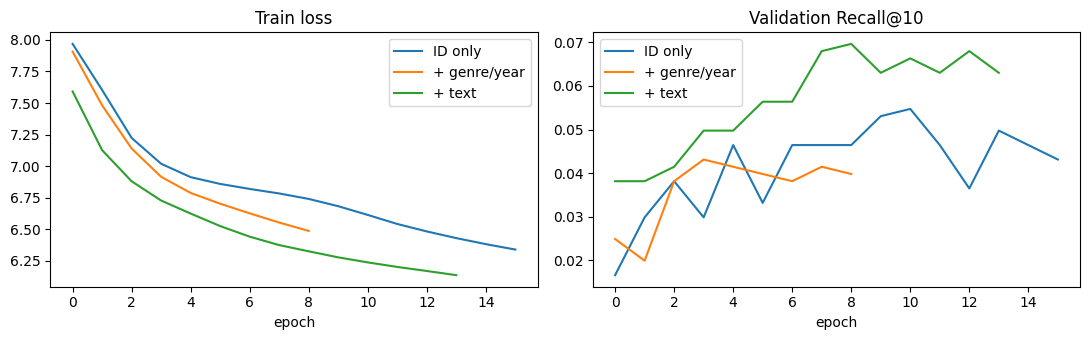

In [10]:
rows = {
    "Popularity": res_pop,
    "Two-Tower (ID only)": metrics_from_scores(model_id.all_scores(), test_df, mask_test),
    "Two-Tower (ID + genre/year)": metrics_from_scores(model_ft.all_scores(), test_df, mask_test),
    "Two-Tower (ID + genre/year + text)": metrics_from_scores(model_tx.all_scores(), test_df, mask_test),
}
results = pd.DataFrame(rows).T.round(4)
results.to_csv("results.csv")
display(results)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for name, h in [("ID only", hist_id), ("+ genre/year", hist_ft), ("+ text", hist_tx)]:
    ax[0].plot([x[0] for x in h], label=name); ax[1].plot([x[1] for x in h], label=name)
ax[0].set_title("Train loss"); ax[1].set_title("Validation Recall@10")
for a in ax: a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.savefig("training_curves.png", dpi=120); plt.show()

## 8) دمو تعاملی (Gradio)

In [11]:
import gradio as gr

# بهترین مدل بر اساس validation (نه test) انتخاب می‌شود
cands = {"id": (model_id, hist_id), "ft": (model_ft, hist_ft), "tx": (model_tx, hist_tx)}
best_key = max(cands, key=lambda k: max(v for _, v in cands[k][1]))
print("demo model:", best_key)
model = cands[best_key][0].eval()
with torch.no_grad():
    ITEM_EMB = model.item(torch.arange(n_items, device=device))
    SCORES = model.all_scores()
titles = movies.title.values
train_by_user = train_df.groupby("u").i.apply(list).to_dict()
seen_all = pd.concat([train_df, val_df, test_df]).groupby("u").i.apply(set).to_dict()

def recommend(user_id, k=10):
    u = u2i.get(int(user_id))
    if u is None:
        return pd.DataFrame({"خطا": [f"کاربر {user_id} در داده نیست"]}), pd.DataFrame()
    s = SCORES[u].clone()
    s[list(seen_all[u])] = -float("inf")
    top = torch.topk(s, int(k)).indices.cpu().numpy()
    recs = pd.DataFrame({"Recommended": titles[top], "Genres": movies.genres.values[top]})
    hist = train_by_user.get(u, [])[-10:]
    history = pd.DataFrame({"Recently liked": titles[hist], "Genres": movies.genres.values[hist]})
    return recs, history

def similar(title, k=10):
    idx = np.where(titles == title)[0]
    if len(idx) == 0: return pd.DataFrame()
    sims = (ITEM_EMB @ ITEM_EMB[idx[0]]).cpu().numpy()
    order = np.argsort(-sims)[1:int(k) + 1]
    return pd.DataFrame({"Similar movies": titles[order], "Similarity": sims[order].round(3)})

popular_titles = list(titles[np.argsort(-item_cnt)[:300]])
with gr.Blocks(title="Two-Tower Movie Recommender") as demo:
    gr.Markdown("# 🎬 Two-Tower Movie Recommender")
    with gr.Tab("Recommend for a user"):
        uid = gr.Number(value=int(user_ids[0]), label="User ID", precision=0)
        kk = gr.Slider(5, 20, value=10, step=1, label="Top-K")
        btn = gr.Button("Recommend")
        out1 = gr.Dataframe(label="Recommendations"); out2 = gr.Dataframe(label="User history")
        btn.click(recommend, [uid, kk], [out1, out2])
    with gr.Tab("Similar movies"):
        dd = gr.Dropdown(popular_titles, value=popular_titles[0], label="Movie")
        k2 = gr.Slider(5, 20, value=10, step=1, label="Top-K")
        b2 = gr.Button("Find similar")
        out3 = gr.Dataframe()
        b2.click(similar, [dd, k2], out3)

demo.launch(share=True, debug=False)

demo model: tx
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3bb39fd9479a85436a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
